# 🛡️ FraudLake — Jour 5 : MLOps, du notebook à la production

| Bronze (J1) | Silver (J2) | Gold (J3) | Stats & ML (J4) | MLOps (J5) |
|:---:|:---:|:---:|:---:|:---:|
| ✅ | ✅ | ✅ | ✅ | **▶ industrialisation du modèle** |

Un modèle qui reste dans un notebook n'a aucune valeur pour la banque. Ce notebook industrialise le scoring de fraude du Jour 4
selon les pratiques MLOps : **reproductibilité**, **traçabilité**, **contrôle qualité automatisé**, **déploiement** et **surveillance**.

```mermaid
flowchart LR
    D["Silver Delta<br/>version figée (Time Travel)"] --> E["① Expériences<br/>4 candidats · MLflow Tracking"]
    E --> Q{"② Portes qualité<br/>performance · équité"}
    Q -->|"validé"| R["③ Registre MLflow<br/>alias @champion"]
    Q -->|"refusé"| X["alias @challenger"]
    R --> P["④ Déploiement<br/>HDFS + API FastAPI :8010"]
    P --> B["⑤ Scoring batch<br/>gold/fraud_alerts + motifs"]
    P --> M["⑥ Surveillance<br/>PSI · performance mensuelle"]
    M -->|"dérive ≥ 0,25"| E
```

| Pratique MLOps | Mise en œuvre dans FraudLake |
|---|---|
| **Versionnage des données** | la version Delta de la Silver est figée et journalisée (`versionAsOf`) : tout entraînement est rejouable à l'identique |
| **Suivi des expériences** | MLflow Tracking : paramètres, métriques, courbes, modèle sérialisé, signature d'entrée |
| **Validation rigoureuse** | découpage **train / validation / test temporel** ; seuil choisi sur la validation, performance rapportée sur le test |
| **Portes de qualité** | PR-AUC, rappel, précision **et équité** (règle des 4/5 sur le rappel par genre et tranche d'âge), évaluées pour chaque candidat |
| **Registre de modèles** | MLflow Model Registry, alias `@champion` / `@challenger` / `@previous_champion` (retour arrière en une ligne) |
| **Pas d'écart entraînement / production** | features, motifs d'alerte et seuils définis **une seule fois** dans le package `fraudlake/`, partagé par le notebook, le batch et l'API |
| **Déploiement** | artefact champion sur HDFS + API REST FastAPI (`/predict`, `/reload` à chaud, `/health`, `/stats`) |
| **Surveillance** | dérive des données (PSI par feature et par mois), dérive du score, performance mensuelle, règle de ré-entraînement |
| **Qualité logicielle** | tests unitaires `pytest` (33 tests) + CI GitHub Actions (`ruff` + `pytest`) |

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
ROOT = Path(os.environ.get("FRAUDLAKE_ROOT", "/workspace"))
sys.path.insert(0, str(ROOT))

import mlflow
import numpy as np
import pandas as pd
import requests
from delta.tables import DeltaTable
from mlflow import MlflowClient
from mlflow.models import infer_signature
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from fraudlake import config as C
from fraudlake.explain import RULES, spark_reason_codes
from fraudlake.monitoring import psi_by_period, retraining_decision

spark = (
    SparkSession.builder
    .appName("J5_MLOps_Industrialisation")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
for noisy in ("mlflow", "py4j", "alembic", "urllib3"):
    logging.getLogger(noisy).setLevel(logging.ERROR)

# --- Charte graphique commune aux notebooks FraudLake --------------------------
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissements pandas 3 / PySpark sans impact

LEGIT, FRAUD, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"   # bleu = légitime, orange = fraude
CLASS_COLORS = {"Légitime": LEGIT, "Fraude": FRAUD}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # palette catégorielle (ordre fixe) pour les 4 candidats

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-447950f5-7836-433b-83fe-829ae769d944;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central


	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central


:: resolution report :: resolve 532ms :: artifacts dl 52ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from central in [default]
	commons-logging#commons-logging;1.3.0 from central in [default]
	commons-pool#commons-pool;1.6 from central in [default]
	io.airlift#aircompressor;2.0.2 from central in [default]
	io.delta#delta-kernel-api;4.4.1 from central in [default]
	io.delta#delta-kernel-defaults;4.4.1 from central in [default]
	io.delta#delta-kernel-unitycatalog;4.4.1 from central in [default]
	io.delta#delta-spark_4.2_2.13;4.4.1 from central in [default]
	io.delta#delta-storage;4.4.1 from centra

26/11/21 08:01:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## 0. Connexion MLflow & gel de la version des données

Le serveur MLflow (service `mlflow`, interface http://localhost:5050) centralise les expériences et le registre. Si le serveur
n'est pas joignable, le notebook bascule automatiquement sur un *backend* local SQLite (`mlops/mlflow.db`) : le TP reste exécutable.

In [2]:
def mlflow_server_up(uri: str) -> bool:
    if not uri.startswith("http"):
        return False
    try:
        return requests.get(f"{uri.rstrip('/')}/health", timeout=3).ok
    except requests.RequestException:
        return False


SERVER_MODE = mlflow_server_up(C.MLFLOW_TRACKING_URI)
TRACKING_URI = C.MLFLOW_TRACKING_URI if SERVER_MODE else C.MLFLOW_FALLBACK_URI
if not SERVER_MODE:
    C.MLOPS_DIR.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
if mlflow.get_experiment_by_name(C.EXPERIMENT_NAME) is None:
    mlflow.create_experiment(C.EXPERIMENT_NAME, artifact_location=None if SERVER_MODE else C.MLFLOW_FALLBACK_ARTIFACTS,
                             tags={"projet": "FraudLake", "domaine": "détection de fraude CB"})
experiment = mlflow.set_experiment(C.EXPERIMENT_NAME)
client = MlflowClient()

# Gel de la version des données : toute la suite lit EXACTEMENT cette version de la Silver
DATA_VERSION = DeltaTable.forPath(spark, C.SILVER_PATH).history(1).select("version").first()[0]
silver = spark.read.format("delta").option("versionAsOf", DATA_VERSION).load(C.SILVER_PATH)

print(f"MLflow            : {TRACKING_URI} ({'serveur' if SERVER_MODE else 'repli local SQLite'})")
print(f"Expérience        : {C.EXPERIMENT_NAME} (id {experiment.experiment_id})")
print(f"Données           : {C.SILVER_PATH} @ version Delta {DATA_VERSION} ({silver.count():,} lignes)")

MLflow            : http://mlflow:5000 (serveur)
Expérience        : fraudlake-scoring (id 1)


Données           : /lakehouse/silver/transactions_enriched @ version Delta 3 (1,852,394 lignes)


## 1. Découpage temporel train / validation / test

Trois périodes **successives** : le modèle n'apprend jamais sur des transactions postérieures à celles sur lesquelles il est jugé.
Le **seuil de décision** est choisi sur la validation, puis la performance est mesurée une seule fois sur le test : choisir le seuil
sur le test reviendrait à « tricher » et surestimerait la performance réelle en production.

In [3]:
EXTRA_COLS = ["trans_num", "card_id", "trans_ts", "trans_month", "amt", "merchant", "state", "dataset_split", "trans_date"]
model_df = silver.select(*C.MODEL_FEATURES, *[c for c in EXTRA_COLS if c not in C.MODEL_FEATURES],
                         F.col("is_fraud").cast("double").alias("label"))

train_period = model_df.filter((F.col("dataset_split") == "train") & (F.col("trans_date") < C.VALIDATION_START))
valid = model_df.filter((F.col("dataset_split") == "train") & (F.col("trans_date") >= C.VALIDATION_START)).cache()
test = model_df.filter(F.col("dataset_split") == "test").cache()
train = train_period.sampleBy("label", fractions={0.0: C.LEGIT_SAMPLING_RATE, 1.0: 1.0}, seed=42).cache()

split_stats = []
for name, df in [("train (sous-échantillonné)", train), ("validation", valid), ("test", test)]:
    r = df.agg(F.count("*").alias("n"), F.sum("label").alias("k"), F.min("trans_date").alias("d0"), F.max("trans_date").alias("d1")).first()
    split_stats.append({"jeu": name, "période": f"{r['d0']} → {r['d1']}", "transactions": r["n"], "fraudes": int(r["k"]),
                        "prévalence": r["k"] / r["n"]})
display(pd.DataFrame(split_stats).style.hide(axis="index").format({"transactions": "{:,}", "fraudes": "{:,}", "prévalence": "{:.2%}"}))

jeu,période,transactions,fraudes,prévalence
train (sous-échantillonné),2019-01-01 → 2020-04-30,"122,512","6,645",5.42%
validation,2020-05-01 → 2020-06-21,"132,090",861,0.65%
test,2020-06-21 → 2020-12-31,"555,719","2,145",0.39%


## 2. ① Suivi des expériences : 4 candidats comparés dans MLflow

| Candidat | Rôle |
|---|---|
| `logreg_baseline` | **référence linéaire** (one-hot + standardisation) : tout modèle complexe doit faire mieux |
| `random_forest` | ensemble de 120 arbres profonds, robuste et peu sensible aux hyperparamètres |
| `gbt_v1` | le modèle du Jour 4 (60 itérations, profondeur 5) |
| `gbt_v2` | variante plus expressive (100 itérations, profondeur 6, sous-échantillonnage 80 %) |
| `gbt_v2_sans_genre` | même modèle **sans la variable `gender`** : teste l'« équité par ignorance » (*fairness through unawareness*) |

Pour chaque candidat, un *run* MLflow enregistre : hyperparamètres, version des données, durée d'entraînement, PR-AUC validation
et test, précision / rappel / F1 au seuil choisi, part du montant fraudé interceptée, **indicateurs d'équité**, courbes, importance
des variables et **modèle sérialisé avec sa signature d'entrée** (schéma des colonnes attendues).

In [4]:
idx_cols = [f"{c}_idx" for c in C.CAT_FEATURES]


def indexers():
    return [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in C.CAT_FEATURES]


def tree_pipeline(clf, cats=tuple(C.CAT_FEATURES)):
    stages = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cats]
    return Pipeline(stages=[*stages, VectorAssembler(inputCols=C.NUM_FEATURES + [f"{c}_idx" for c in cats], outputCol="features"), clf])


def linear_pipeline(clf):
    ohe_cols = [f"{c}_ohe" for c in C.CAT_FEATURES]
    return Pipeline(stages=[
        *indexers(), OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols),
        VectorAssembler(inputCols=C.NUM_FEATURES + ohe_cols, outputCol="raw_features"),
        StandardScaler(inputCol="raw_features", outputCol="features", withMean=False, withStd=True), clf,
    ])


CANDIDATES = [
    ("logreg_baseline", "Régression logistique", linear_pipeline,
     LogisticRegression(labelCol="label", maxIter=200, regParam=0.001, elasticNetParam=0.0)),
    ("random_forest", "Forêt aléatoire", tree_pipeline,
     RandomForestClassifier(labelCol="label", numTrees=120, maxDepth=10, featureSubsetStrategy="sqrt", seed=42)),
    ("gbt_v1", "Gradient-Boosted Trees", tree_pipeline,
     GBTClassifier(labelCol="label", maxIter=60, maxDepth=5, stepSize=0.1, seed=42)),
    ("gbt_v2", "Gradient-Boosted Trees", tree_pipeline,
     GBTClassifier(labelCol="label", maxIter=100, maxDepth=6, stepSize=0.08, subsamplingRate=0.8, seed=42)),
    ("gbt_v2_sans_genre", "Gradient-Boosted Trees", lambda clf: tree_pipeline(clf, cats=("category",)),
     GBTClassifier(labelCol="label", maxIter=100, maxDepth=6, stepSize=0.08, subsamplingRate=0.8, seed=42)),
]

PR_EVAL = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")
ROC_EVAL = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
THRESHOLDS = np.round(np.arange(0.02, 0.99, 0.02), 2)


def score(model, df):
    return model.transform(df).withColumn("fraud_score", vector_to_array("probability")[1])


def threshold_curve(pred) -> pd.DataFrame:
    """Matrice de confusion + montants interceptés pour 49 seuils, en un seul passage Spark."""
    exprs = []
    for i, t in enumerate(THRESHOLDS):
        hit = F.col("fraud_score") >= float(t)
        exprs += [F.sum((hit & (F.col("label") == 1)).cast("int")).alias(f"tp{i}"),
                  F.sum((hit & (F.col("label") == 0)).cast("int")).alias(f"fp{i}"),
                  F.sum(F.when(hit & (F.col("label") == 1), F.col("amt")).otherwise(0)).alias(f"amt{i}")]
    a = pred.agg(F.sum("label").alias("pos"), F.count("*").alias("n"),
                 F.sum(F.when(F.col("label") == 1, F.col("amt")).otherwise(0)).alias("fraud_amt"), *exprs).first()
    curve = pd.DataFrame({"threshold": THRESHOLDS, "tp": [a[f"tp{i}"] for i in range(len(THRESHOLDS))],
                          "fp": [a[f"fp{i}"] for i in range(len(THRESHOLDS))],
                          "amt_caught": [float(a[f"amt{i}"]) for i in range(len(THRESHOLDS))]})
    curve["fn"], curve["tn"] = a["pos"] - curve["tp"], (a["n"] - a["pos"]) - curve["fp"]
    curve["alerts"] = curve["tp"] + curve["fp"]
    curve["precision"] = (curve["tp"] / curve["alerts"].replace(0, np.nan)).fillna(1.0)
    curve["recall"] = curve["tp"] / a["pos"]
    curve["f1"] = (2 * curve["precision"] * curve["recall"] / (curve["precision"] + curve["recall"])).fillna(0.0)
    curve["amt_caught_share"] = curve["amt_caught"] / a["fraud_amt"]
    curve["alert_rate"] = curve["alerts"] / a["n"]
    return curve


AGE_BAND = (F.when(F.col("age") < 30, "< 30 ans").when(F.col("age") < 50, "30–49 ans")
            .when(F.col("age") < 70, "50–69 ans").otherwise("70 ans et +"))


def fairness_table(pred, thr: float) -> pd.DataFrame:
    """Rappel, précision et taux d'alerte par genre et par tranche d'âge au seuil `thr`."""
    p = pred.withColumn("alert", (F.col("fraud_score") >= thr).cast("int"))
    rows = []
    for dim, col in [("genre", F.col("gender")), ("tranche d'âge", AGE_BAND)]:
        for r in (p.groupBy(col.alias("groupe")).agg(F.sum("label").alias("k"), F.sum(F.col("label") * F.col("alert")).alias("tp"),
                                                     F.sum("alert").alias("a"), F.count("*").alias("n")).collect()):
            rows.append({"dimension": dim, "groupe": r["groupe"], "transactions": r["n"], "fraudes": int(r["k"]),
                         "rappel": r["tp"] / r["k"] if r["k"] else np.nan, "précision": r["tp"] / r["a"] if r["a"] else np.nan,
                         "taux_alerte": r["a"] / r["n"]})
    return pd.DataFrame(rows).sort_values(["dimension", "groupe"]).reset_index(drop=True)


def fairness_summary(fair: pd.DataFrame) -> tuple[float, float]:
    """(ratio rappel min / max, écart max) sur les groupes d'au moins 50 fraudes, toutes dimensions confondues."""
    ok = fair[fair["fraudes"] >= 50]
    ratio = min(g["rappel"].min() / g["rappel"].max() for _, g in ok.groupby("dimension"))
    gap = max(g["rappel"].max() - g["rappel"].min() for _, g in ok.groupby("dimension"))
    return float(ratio), float(gap)


def gate_results(m: dict) -> dict:
    g = C.QUALITY_GATES
    return {"PR-AUC test": m["test_pr_auc"] >= g["test_pr_auc"], "Rappel au seuil": m["test_recall"] >= g["test_recall"],
            "Précision au seuil": m["test_precision"] >= g["test_precision"],
            "Équité (règle des 4/5)": m["fairness_recall_ratio"] >= g["fairness_recall_ratio"]}


def explicit_params(clf) -> dict:
    return {p.name: v for p, v in clf.extractParamMap().items() if clf.isSet(p) and p.name not in ("labelCol",)}

In [5]:
signature_example = test.select(*C.MODEL_FEATURES).limit(5).toPandas()
signature = infer_signature(signature_example, np.zeros(len(signature_example)))
results, fitted, curves, fairness_by_model = [], {}, {}, {}

for key, family, make_pipeline, clf in CANDIDATES:
    with mlflow.start_run(run_name=key) as run:
        mlflow.set_tags({"stage": "experimentation", "model_family": family, "projet": "FraudLake"})
        mlflow.log_params({**explicit_params(clf), "candidate": key, "data_version": DATA_VERSION, "silver_path": C.SILVER_PATH,
                           "validation_start": C.VALIDATION_START, "legit_sampling_rate": C.LEGIT_SAMPLING_RATE,
                           "n_features": len(C.MODEL_FEATURES), "features": ",".join(C.MODEL_FEATURES)})
        t0 = time.perf_counter()
        model = make_pipeline(clf).fit(train)
        train_s = time.perf_counter() - t0

        pv, pt = score(model, valid).cache(), score(model, test).cache()
        valid_pr = PR_EVAL.evaluate(pv)
        curve_valid = threshold_curve(pv)
        thr = float(curve_valid.loc[curve_valid["f1"].idxmax(), "threshold"])       # seuil choisi sur la VALIDATION
        curve_test = threshold_curve(pt)
        at = curve_test.set_index("threshold").loc[thr]
        metrics = {"train_seconds": train_s, "valid_pr_auc": valid_pr, "test_pr_auc": PR_EVAL.evaluate(pt),
                   "test_roc_auc": ROC_EVAL.evaluate(pt), "threshold": thr, "test_precision": at["precision"],
                   "test_recall": at["recall"], "test_f1": at["f1"], "test_alert_rate": at["alert_rate"],
                   "test_amount_caught_share": at["amt_caught_share"]}
        fair = fairness_table(pt, thr)
        metrics["fairness_recall_ratio"], metrics["fairness_recall_gap"] = fairness_summary(fair)
        gates_ok = all(gate_results(metrics).values())
        mlflow.log_metrics(metrics)
        mlflow.set_tag("quality_gates", "passed" if gates_ok else "failed")
        mlflow.log_text(fair.to_csv(index=False), "evaluation/fairness.csv")

        fig, ax = plt.subplots(figsize=(5, 4))
        ax.plot(curve_valid["recall"], curve_valid["precision"], color=LEGIT, lw=2, label="validation")
        ax.plot(curve_test["recall"], curve_test["precision"], color=FRAUD, lw=2, label="test")
        ax.scatter([at["recall"]], [at["precision"]], color="#0b0b0b", zorder=3, label=f"seuil {thr:.2f}")
        ax.set(xlabel="rappel", ylabel="précision", title=f"{key} — courbe précision-rappel", xlim=(0, 1.02), ylim=(0, 1.02))
        ax.legend()
        mlflow.log_figure(fig, "plots/pr_curve.png")
        plt.close(fig)
        mlflow.log_text(curve_test.to_csv(index=False), "evaluation/threshold_curve_test.csv")
        clf_model = model.stages[-1]
        if hasattr(clf_model, "featureImportances"):
            names = [c.removesuffix("_idx") for c in model.stages[-2].getInputCols()]
            imp = pd.DataFrame({"feature": names, "importance": clf_model.featureImportances.toArray()}).sort_values("importance", ascending=False)
            mlflow.log_text(imp.to_csv(index=False), "evaluation/feature_importance.csv")
        spark.sparkContext.setLogLevel("OFF")   # MLflow tente d'abord une écriture directe (refusée par Hadoop) puis passe par HDFS
        mlflow.spark.log_model(model, artifact_path="model", signature=signature, dfs_tmpdir=C.MLFLOW_DFS_TMP)
        spark.sparkContext.setLogLevel("ERROR")

        results.append({"candidate": key, "family": family, "run_id": run.info.run_id, **metrics, "gates_passed": gates_ok})
        fitted[key], curves[key], fairness_by_model[key] = model, curve_test, fair
        pv.unpersist()
        pt.unpersist()
        print(f"{'✅' if gates_ok else '⛔'} {key:<18} PR-AUC valid {valid_pr:.3f} | test {metrics['test_pr_auc']:.3f} | seuil {thr:.2f} | "
              f"P {at['precision']:.0%} R {at['recall']:.0%} | équité 4/5 {metrics['fairness_recall_ratio']:.2f} | {train_s:4.0f} s")

experiments = pd.DataFrame(results)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


⛔ logreg_baseline    PR-AUC valid 0.542 | test 0.403 | seuil 0.56 | P 45% R 66% | équité 4/5 0.84 |    7 s
🏃 View run logreg_baseline at: http://mlflow:5000/#/experiments/1/runs/0e9c9d3dbd0149159b15e4f4121cbb75
🧪 View experiment at: http://mlflow:5000/#/experiments/1


✅ random_forest      PR-AUC valid 0.937 | test 0.898 | seuil 0.68 | P 83% R 86% | équité 4/5 0.88 |   32 s
🏃 View run random_forest at: http://mlflow:5000/#/experiments/1/runs/c1a99202aeba44d8b8aeebe1ac2498a0
🧪 View experiment at: http://mlflow:5000/#/experiments/1


✅ gbt_v1             PR-AUC valid 0.933 | test 0.889 | seuil 0.80 | P 80% R 85% | équité 4/5 0.88 |   40 s
🏃 View run gbt_v1 at: http://mlflow:5000/#/experiments/1/runs/728f20ed891248edb2ff5c922daf6969
🧪 View experiment at: http://mlflow:5000/#/experiments/1


✅ gbt_v2             PR-AUC valid 0.956 | test 0.926 | seuil 0.88 | P 89% R 86% | équité 4/5 0.87 |  107 s
🏃 View run gbt_v2 at: http://mlflow:5000/#/experiments/1/runs/a4afeba4c2e346f193b80d398d337f7b
🧪 View experiment at: http://mlflow:5000/#/experiments/1


✅ gbt_v2_sans_genre  PR-AUC valid 0.954 | test 0.923 | seuil 0.88 | P 88% R 85% | équité 4/5 0.85 |  103 s
🏃 View run gbt_v2_sans_genre at: http://mlflow:5000/#/experiments/1/runs/416fd98e24394479b85c67013c42c159
🧪 View experiment at: http://mlflow:5000/#/experiments/1


candidate,valid_pr_auc,test_pr_auc,test_roc_auc,threshold,test_precision,test_recall,test_amount_caught_share,fairness_recall_ratio,gates_passed,train_seconds
logreg_baseline,0.542,0.403,0.9777,0.56,45.0%,66.5%,82.5%,0.84,False,7 s
random_forest,0.937,0.898,0.9961,0.68,82.9%,85.8%,94.0%,0.88,True,32 s
gbt_v1,0.933,0.889,0.9952,0.80,79.6%,85.1%,91.6%,0.88,True,40 s
gbt_v2,0.956,0.926,0.9972,0.88,88.9%,85.5%,91.1%,0.87,True,107 s
gbt_v2_sans_genre,0.954,0.923,0.9973,0.88,87.8%,85.2%,90.5%,0.85,True,103 s


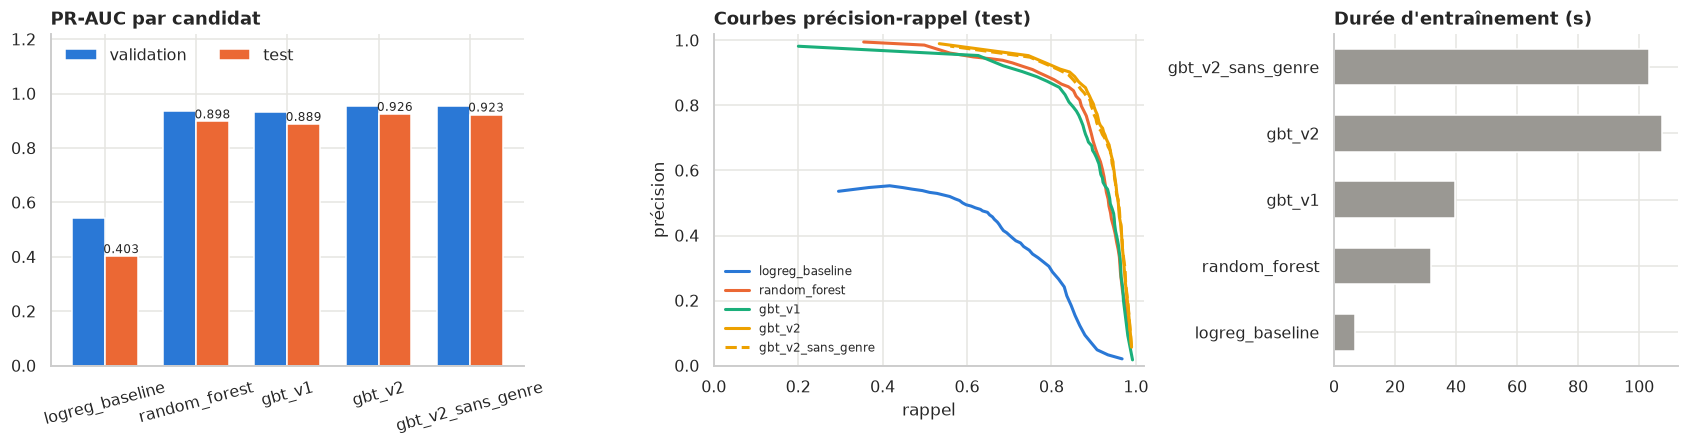

🔗 Comparer les runs dans MLflow : http://localhost:5050/#/experiments/1


In [6]:
# Sélection : meilleure PR-AUC de VALIDATION parmi les candidats qui franchissent toutes les portes
eligible = experiments[experiments["gates_passed"]]
BEST = (eligible if len(eligible) else experiments).sort_values("valid_pr_auc", ascending=False).iloc[0]
# NB : on ne choisit JAMAIS sur la PR-AUC de test (sinon le test devient un second jeu de validation et la performance annoncée est biaisée)
display(
    experiments[["candidate", "valid_pr_auc", "test_pr_auc", "test_roc_auc", "threshold", "test_precision",
                 "test_recall", "test_amount_caught_share", "fairness_recall_ratio", "gates_passed", "train_seconds"]]
    .style.hide(axis="index")
    .format({"valid_pr_auc": "{:.3f}", "test_pr_auc": "{:.3f}", "test_roc_auc": "{:.4f}", "threshold": "{:.2f}",
             "test_precision": "{:.1%}", "test_recall": "{:.1%}", "test_amount_caught_share": "{:.1%}",
             "fairness_recall_ratio": "{:.2f}", "train_seconds": "{:.0f} s"})
    .apply(lambda r: ["background-color: #eb683422; font-weight: 600" if r["candidate"] == BEST["candidate"] else "" for _ in r], axis=1)
    .set_caption(f"Comparaison des candidats — retenu : {BEST['candidate']} (meilleure PR-AUC de validation parmi les candidats conformes)")
)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 0.8]})
x = np.arange(len(experiments))
axes[0].bar(x - 0.18, experiments["valid_pr_auc"], width=0.36, color=LEGIT, label="validation")
axes[0].bar(x + 0.18, experiments["test_pr_auc"], width=0.36, color=FRAUD, label="test")
for i, v in enumerate(experiments["test_pr_auc"]):
    axes[0].text(i + 0.18, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x, experiments["candidate"], rotation=15)
axes[0].set_ylim(0, 1.22)
axes[0].set_title("PR-AUC par candidat")
axes[0].legend(loc="upper left", ncol=2)
for i, (key, curve) in enumerate(curves.items()):
    style = {"color": SERIES[i], "ls": "-"} if i < len(SERIES) else {"color": SERIES[-1], "ls": "--"}   # variante sans genre en pointillé
    axes[1].plot(curve["recall"], curve["precision"], lw=2, label=key, **style)
axes[1].set(xlim=(0, 1.02), ylim=(0, 1.02), xlabel="rappel", ylabel="précision", title="Courbes précision-rappel (test)")
axes[1].legend(fontsize=8)
axes[2].barh(experiments["candidate"], experiments["train_seconds"], color=NEUTRAL, height=0.55)
axes[2].set_title("Durée d'entraînement (s)")
plt.tight_layout()
plt.show()
print(f"🔗 Comparer les runs dans MLflow : http://localhost:5050/#/experiments/{experiment.experiment_id}" if SERVER_MODE else "")

> **Lecture.** Les modèles d'arbres écrasent la référence linéaire (PR-AUC test ≈ 0,89 – 0,93 contre 0,40) : la fraude dépend
> d'**interactions non linéaires** (montant × nuit × catégorie × vélocité) qu'une régression logistique ne capte pas. `gbt_v2` est
> retenu car il a la meilleure PR-AUC **de validation** (0,956) ; il est aussi le meilleur sur le test (0,926, précision 89 %, rappel 86 %).
> Les modèles d'arbres restent dans un mouchoir de poche : selon l'échantillonnage, leur classement peut s'inverser (lors d'un essai
> local, c'est la forêt aléatoire qui l'emportait). C'est pourquoi le choix se fait **toujours sur la validation** : choisir sur le
> test le transformerait en second jeu de validation et rendrait la performance annoncée **biaisée**.

## 3. ② Portes de qualité : performance **et** équité

Avant toute promotion, un candidat doit franchir des **portes automatiques** (définies dans `fraudlake/config.py`). En plus de la
performance, on vérifie l'**équité** : le modèle ne doit pas protéger nettement moins bien un groupe de clients (genre, tranche d'âge).
Critère retenu : la **règle des quatre cinquièmes** — le rappel du groupe le moins bien servi doit atteindre au moins 80 % du rappel
du groupe le mieux servi (critère de référence de l'EEOC américaine pour l'impact disproportionné).

,PR-AUC test,Rappel au seuil,Précision au seuil,Équité (règle des 4/5)
candidat,,,,
logreg_baseline,❌,❌,❌,✅
random_forest,✅,✅,✅,✅
gbt_v1,✅,✅,✅,✅
gbt_v2,✅,✅,✅,✅
gbt_v2_sans_genre,✅,✅,✅,✅


porte,valeur,seuil,sens,résultat
PR-AUC test,0.926,0.75,≥,✅ validée
Rappel au seuil,0.855,0.70,≥,✅ validée
Précision au seuil,0.889,0.50,≥,✅ validée
Équité : rappel min / max (règle des 4/5),0.872,0.80,≥,✅ validée


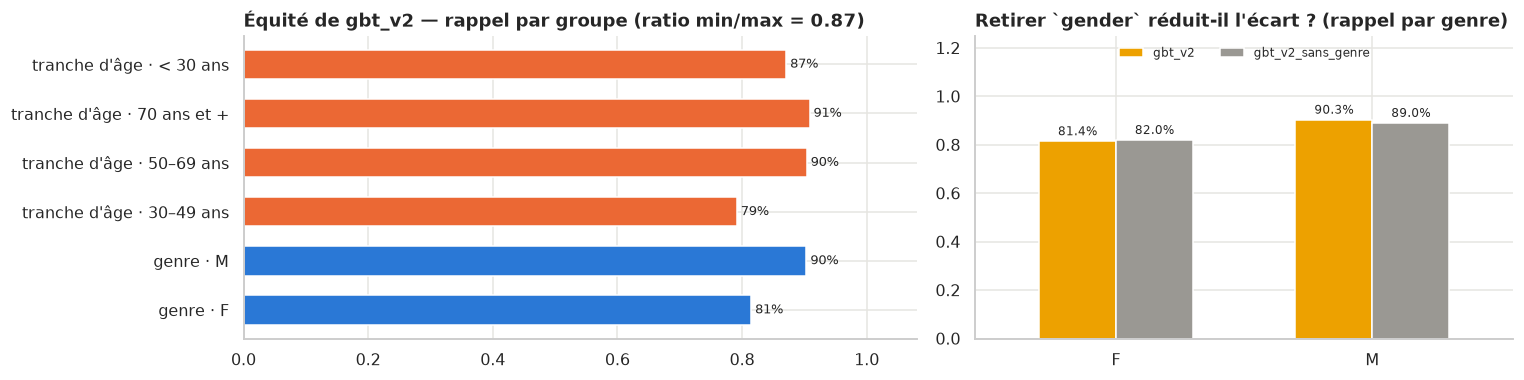

Décision des portes : ✅ gbt_v2 validé


In [7]:
best_model = fitted[BEST["candidate"]]
THRESHOLD = float(BEST["threshold"])
fairness = fairness_by_model[BEST["candidate"]]
ratio, max_gap = float(BEST["fairness_recall_ratio"]), float(BEST["fairness_recall_gap"])

# Tableau de bord des portes pour TOUS les candidats
gate_matrix = pd.DataFrame({r["candidate"]: gate_results(r) for _, r in experiments.iterrows()}).T
display(gate_matrix.replace({True: "✅", False: "❌"}).rename_axis("candidat")
        .style.set_caption("Portes de qualité par candidat (PR-AUC ≥ 0,75 · rappel ≥ 70 % · précision ≥ 50 % · ratio de rappel ≥ 0,80)"))

g = C.QUALITY_GATES
gates = pd.DataFrame([
    {"porte": "PR-AUC test", "valeur": BEST["test_pr_auc"], "seuil": g["test_pr_auc"], "sens": "≥"},
    {"porte": "Rappel au seuil", "valeur": BEST["test_recall"], "seuil": g["test_recall"], "sens": "≥"},
    {"porte": "Précision au seuil", "valeur": BEST["test_precision"], "seuil": g["test_precision"], "sens": "≥"},
    {"porte": "Équité : rappel min / max (règle des 4/5)", "valeur": ratio, "seuil": g["fairness_recall_ratio"], "sens": "≥"},
])
gates["résultat"] = np.where(gates["valeur"] >= gates["seuil"], "✅ validée", "❌ refusée")
GATES_OK = bool(BEST["gates_passed"])
display(gates.style.hide(axis="index").format({"valeur": "{:.3f}", "seuil": "{:.2f}"})
        .set_caption(f"Candidat retenu : {BEST['candidate']}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})
labels = [f"{d} · {gr}" for d, gr in zip(fairness["dimension"], fairness["groupe"], strict=True)]
axes[0].barh(labels, fairness["rappel"], color=[LEGIT if d == "genre" else FRAUD for d in fairness["dimension"]], height=0.6)
for y, v in enumerate(fairness["rappel"]):
    axes[0].text(v, y, f" {v:.0%}", va="center", fontsize=8.5)
axes[0].set_xlim(0, 1.08)
axes[0].set_title(f"Équité de {BEST['candidate']} — rappel par groupe (ratio min/max = {ratio:.2f})")
cmp = pd.DataFrame({k: fairness_by_model[k].set_index(["dimension", "groupe"])["rappel"] for k in ("gbt_v2", "gbt_v2_sans_genre")
                    if k in fairness_by_model}).loc["genre"]
cmp.plot.bar(ax=axes[1], color=[SERIES[3], NEUTRAL], rot=0, width=0.6)
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="{:.1%}", fontsize=8, padding=2)
axes[1].set_ylim(0, 1.25)
axes[1].set_title("Retirer `gender` réduit-il l'écart ? (rappel par genre)")
axes[1].set_xlabel("")
axes[1].legend(fontsize=8, loc="upper center", ncol=2)
plt.tight_layout()
plt.show()
print("Décision des portes :", f"✅ {BEST['candidate']} validé" if GATES_OK else "❌ aucun candidat ne franchit toutes les portes")

> **Lecture équité.** Le rappel est plus faible pour les femmes (81 %) que pour les hommes (90 %), et pour les 30–49 ans (79 %) que
> pour les 70 ans et plus (91 %). Le ratio min/max (0,87) respecte la règle des 4/5, donc le modèle est **promouvable**, mais l'écart est
> réel et **documenté** dans la fiche modèle. Point important : le candidat **sans la variable `gender`** ne fait pas mieux (ratio 0,85).
> L'écart ne vient donc pas de l'utilisation du genre par le modèle, mais de **profils de fraude différents** selon les groupes. Supprimer une variable
> sensible ne suffit pas à rendre un modèle équitable : il faut **mesurer** le résultat, ce que font ces portes à chaque version.

## 4. ③ Registre de modèles : champion / challenger

Le candidat est enregistré comme **nouvelle version** du modèle `fraudlake-scoring`. Il ne devient `@champion` (modèle servi en
production) que s'il passe les portes **et** fait au moins aussi bien que le champion actuel ; sinon il est étiqueté `@challenger`.
L'ancien champion reçoit l'alias `@previous_champion` : **un retour arrière se fait en une ligne** (`set_registered_model_alias`).

In [8]:
best_run_id = BEST["run_id"]
mv = mlflow.register_model(f"runs:/{best_run_id}/model", C.REGISTERED_MODEL)
client.update_registered_model(C.REGISTERED_MODEL, description="Scoring de fraude CB — FraudLake (Spark MLlib).")
client.update_model_version(C.REGISTERED_MODEL, mv.version,
                            description=f"{BEST['candidate']} · données Silver v{DATA_VERSION} · seuil {THRESHOLD:.2f}")
for k, v in {"candidate": BEST["candidate"], "data_version": str(DATA_VERSION), "threshold": f"{THRESHOLD:.2f}",
             "validation_status": "passed" if GATES_OK else "failed", "fairness_recall_ratio": f"{ratio:.3f}"}.items():
    client.set_model_version_tag(C.REGISTERED_MODEL, mv.version, k, v)

try:
    current = client.get_model_version_by_alias(C.REGISTERED_MODEL, "champion")
    current_pr = client.get_run(current.run_id).data.metrics.get("test_pr_auc", 0.0)
except Exception:
    current, current_pr = None, None

PROMOTED = GATES_OK and (current is None or BEST["test_pr_auc"] >= current_pr - 0.005)
if PROMOTED:
    if current is not None and current.version != mv.version:
        client.set_registered_model_alias(C.REGISTERED_MODEL, "previous_champion", current.version)
    client.set_registered_model_alias(C.REGISTERED_MODEL, "champion", mv.version)
    verdict = f"🏆 version {mv.version} promue @champion" + (f" (remplace v{current.version}, PR-AUC {current_pr:.3f})" if current else "")
else:
    client.set_registered_model_alias(C.REGISTERED_MODEL, "challenger", mv.version)
    verdict = f"🥈 version {mv.version} étiquetée @challenger (champion actuel conservé)"
print(verdict)

registry_rows = []
for found in client.search_model_versions(f"name='{C.REGISTERED_MODEL}'"):
    v = client.get_model_version(C.REGISTERED_MODEL, found.version)      # renvoie aussi les alias
    m = client.get_run(v.run_id).data.metrics
    registry_rows.append({"version": int(v.version), "aliases": ", ".join(getattr(v, "aliases", []) or []) or "—",
                          "candidate": v.tags.get("candidate"), "data_version": v.tags.get("data_version"),
                          "validation": v.tags.get("validation_status"), "test_pr_auc": m.get("test_pr_auc"),
                          "test_recall": m.get("test_recall"), "test_precision": m.get("test_precision"),
                          "threshold": m.get("threshold"), "run_id": v.run_id,
                          "created_at": datetime.fromtimestamp(v.creation_timestamp / 1000, tz=timezone.utc).strftime("%Y-%m-%d %H:%M")})
registry = pd.DataFrame(registry_rows).sort_values("version", ascending=False)
display(registry.drop(columns="run_id").style.hide(axis="index").format(
    {"test_pr_auc": "{:.3f}", "test_recall": "{:.1%}", "test_precision": "{:.1%}", "threshold": "{:.2f}"}, na_rep="—"))

Successfully registered model 'fraudlake-scoring'.
Created version '1' of model 'fraudlake-scoring'.


🏆 version 1 promue @champion


version,aliases,candidate,data_version,validation,test_pr_auc,test_recall,test_precision,threshold,created_at
1,champion,gbt_v2,3,passed,0.926,85.5%,88.9%,0.88,2026-11-21 08:11


### Fiche du modèle (*model card*)
La fiche documente l'usage prévu, les données, les performances, l'équité et les limites. Elle est journalisée dans MLflow,
écrite dans `mlops/MODEL_CARD.md` et publiée en Gold pour le dashboard.

In [9]:
try:
    champion_version = int(client.get_model_version_by_alias(C.REGISTERED_MODEL, "champion").version)
except Exception:
    champion_version = None   # aucun modèle n'a encore franchi les portes de qualité
fair_md = "\n".join(f"| {r.dimension} | {r.groupe} | {r.fraudes:,} | {r.rappel:.1%} | {r.précision:.1%} |" for r in fairness.itertuples())
gates_md = "\n".join(f"| {r.porte} | {r.valeur:.3f} | {r.sens} {r.seuil:.2f} | {r.résultat} |" for r in gates.itertuples())
MODEL_CARD = f"""# Fiche modèle — `{C.REGISTERED_MODEL}` v{mv.version}

| | |
|---|---|
| **Statut** | {"@champion (production)" if PROMOTED else "@challenger"} — {datetime.now(timezone.utc):%Y-%m-%d} |
| **Algorithme** | {BEST['family']} (`{BEST['candidate']}`), Spark MLlib |
| **Usage prévu** | Prioriser les transactions CB à investiguer / bloquer. Score = rang de risque (non calibré). |
| **Hors périmètre** | Décision automatique sans revue humaine ; autres pays / moyens de paiement. |
| **Données** | `{C.SILVER_PATH}` @ version Delta {DATA_VERSION} — train 2019-01 → 2020-04 (légitimes sous-échantillonnés à {C.LEGIT_SAMPLING_RATE:.0%}), validation 2020-05 → 2020-06, test 2020-06 → 2020-12 |
| **Features** | {len(C.MODEL_FEATURES)} : {", ".join(C.MODEL_FEATURES)} |
| **Seuil** | {THRESHOLD:.2f} (F1 maximal sur la validation) |

## Performance (test, transactions jamais vues)
| PR-AUC | ROC-AUC | Précision | Rappel | Montant fraudé intercepté | Taux d'alerte |
|---|---|---|---|---|---|
| {BEST['test_pr_auc']:.3f} | {BEST['test_roc_auc']:.4f} | {BEST['test_precision']:.1%} | {BEST['test_recall']:.1%} | {BEST['test_amount_caught_share']:.1%} | {BEST['test_alert_rate']:.2%} |

## Portes de qualité
| Porte | Valeur | Exigence | Résultat |
|---|---|---|---|
{gates_md}

## Équité (rappel par groupe)
| Dimension | Groupe | Fraudes | Rappel | Précision |
|---|---|---|---|---|
{fair_md}

## Limites & risques
- Données **synthétiques** (simulateur Sparkov) : motifs plus nets qu'en réalité, à revalider sur données réelles.
- Entraînement sous-échantillonné : recalibrer (Platt / isotonique) avant d'interpréter le score comme une probabilité.
- Dérive attendue (nouveaux modes opératoires, inflation) : surveillance PSI mensuelle et ré-entraînement si PSI ≥ {C.PSI_ALERT}.
- Équité : ratio de rappel min/max = {ratio:.2f} (écart {max_gap:.1%}). Retirer `gender` ne réduit pas l'écart (testé : `gbt_v2_sans_genre`) — il provient de profils de fraude différents selon l'âge et le genre ; à surveiller à chaque version.
"""
client.log_text(best_run_id, MODEL_CARD, "model_card.md")
C.MLOPS_DIR.mkdir(parents=True, exist_ok=True)
(C.MLOPS_DIR / "MODEL_CARD.md").write_text(MODEL_CARD, encoding="utf-8")
from IPython.display import Markdown
display(Markdown(MODEL_CARD))

# Fiche modèle — `fraudlake-scoring` v1

| | |
|---|---|
| **Statut** | @champion (production) — 2026-11-21 |
| **Algorithme** | Gradient-Boosted Trees (`gbt_v2`), Spark MLlib |
| **Usage prévu** | Prioriser les transactions CB à investiguer / bloquer. Score = rang de risque (non calibré). |
| **Hors périmètre** | Décision automatique sans revue humaine ; autres pays / moyens de paiement. |
| **Données** | `/lakehouse/silver/transactions_enriched` @ version Delta 3 — train 2019-01 → 2020-04 (légitimes sous-échantillonnés à 10%), validation 2020-05 → 2020-06, test 2020-06 → 2020-12 |
| **Features** | 15 : amt_log, hour, is_night, is_weekend, is_online, age, distance_km, city_pop_log, txn_count_24h, amt_sum_24h, secs_since_prev_txn, amt_ratio_to_card_mean, days_to_holiday, category, gender |
| **Seuil** | 0.88 (F1 maximal sur la validation) |

## Performance (test, transactions jamais vues)
| PR-AUC | ROC-AUC | Précision | Rappel | Montant fraudé intercepté | Taux d'alerte |
|---|---|---|---|---|---|
| 0.926 | 0.9972 | 88.9% | 85.5% | 91.1% | 0.37% |

## Portes de qualité
| Porte | Valeur | Exigence | Résultat |
|---|---|---|---|
| PR-AUC test | 0.926 | ≥ 0.75 | ✅ validée |
| Rappel au seuil | 0.855 | ≥ 0.70 | ✅ validée |
| Précision au seuil | 0.889 | ≥ 0.50 | ✅ validée |
| Équité : rappel min / max (règle des 4/5) | 0.872 | ≥ 0.80 | ✅ validée |

## Équité (rappel par groupe)
| Dimension | Groupe | Fraudes | Rappel | Précision |
|---|---|---|---|---|
| genre | F | 1,164 | 81.4% | 86.9% |
| genre | M | 981 | 90.3% | 91.1% |
| tranche d'âge | 30–49 ans | 849 | 79.2% | 83.1% |
| tranche d'âge | 50–69 ans | 685 | 90.4% | 93.2% |
| tranche d'âge | 70 ans et + | 294 | 90.8% | 96.0% |
| tranche d'âge | < 30 ans | 317 | 87.1% | 88.2% |

## Limites & risques
- Données **synthétiques** (simulateur Sparkov) : motifs plus nets qu'en réalité, à revalider sur données réelles.
- Entraînement sous-échantillonné : recalibrer (Platt / isotonique) avant d'interpréter le score comme une probabilité.
- Dérive attendue (nouveaux modes opératoires, inflation) : surveillance PSI mensuelle et ré-entraînement si PSI ≥ 0.25.
- Équité : ratio de rappel min/max = 0.87 (écart 11.7%). Retirer `gender` ne réduit pas l'écart (testé : `gbt_v2_sans_genre`) — il provient de profils de fraude différents selon l'âge et le genre ; à surveiller à chaque version.


## 5. ④ Déploiement : artefact champion sur HDFS + API REST

Le champion est exporté vers un **emplacement de déploiement stable** sur HDFS (`/lakehouse/models/fraudlake_scoring/champion`)
avec ses métadonnées (version, seuil, métriques, version des données). L'API `fraud-api` (FastAPI, http://localhost:8010/docs) charge
cet artefact ; l'appel `POST /reload` bascule sur le nouveau champion **sans redémarrer le service**.

In [10]:
if PROMOTED:
    best_model.write().overwrite().save(C.CHAMPION_PATH)
    champion_meta = {
        "model_name": C.REGISTERED_MODEL, "model_version": str(mv.version), "candidate": BEST["candidate"],
        "run_id": best_run_id, "threshold": THRESHOLD, "data_version": DATA_VERSION,
        "test_pr_auc": round(float(BEST["test_pr_auc"]), 4), "test_recall": round(float(BEST["test_recall"]), 4),
        "test_precision": round(float(BEST["test_precision"]), 4), "features": C.MODEL_FEATURES,
        "promoted_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    spark.createDataFrame([(json.dumps(champion_meta, ensure_ascii=False),)], ["value"]) \
        .coalesce(1).write.mode("overwrite").text(C.CHAMPION_META_PATH)
    print(f"📦 Champion v{mv.version} déployé dans {C.CHAMPION_PATH}")
else:
    print("ℹ️ Pas de nouveau déploiement : le champion en place reste servi.")

from serving.schemas import EXAMPLE

try:
    health = requests.post(f"{C.API_URL}/reload", timeout=180).json()
    print("🔄 API rechargée :", health)
    answer = requests.post(f"{C.API_URL}/predict", json=EXAMPLE, timeout=60).json()
    print("\n=== Exemple de requête POST /predict ===")
    print(json.dumps(answer, indent=2, ensure_ascii=False))
except requests.RequestException as exc:
    print(f"ℹ️ API non joignable ({C.API_URL}) : démarrez-la avec `docker compose up -d fraud-api` puis `task api:smoke`.")

📦 Champion v1 déployé dans /lakehouse/models/fraudlake_scoring/champion


🔄 API rechargée : {'status': 'ok', 'model_loaded': True, 'model_version': '1', 'detail': None}



=== Exemple de requête POST /predict ===
{
  "transaction_id": "demo-0001",
  "fraud_score": 0.98519,
  "decision": "ALERTE",
  "priority": "critique",
  "threshold": 0.88,
  "reasons": [
    "Montant élevé (962 $)",
    "Dépenses cumulées sur 24 h anormales (2210 $)",
    "Montant 11.8 fois supérieur à l'habitude de la carte",
    "Transaction nocturne (22 h – 4 h)",
    "Catégorie à risque élevé (shopping_net)"
  ],
  "model_version": "1"
}


## 6. ⑤ Scoring batch : file d'alertes priorisée et expliquée

Le champion déployé score toute la période de test. Chaque alerte reçoit une **priorité** et des **motifs lisibles** (*reason codes*)
issus des règles partagées de `fraudlake/explain.py` — l'analyste sait immédiatement *pourquoi* la transaction est suspecte.

| Motif | Règle | Lift (taux de fraude ciblé / taux de base) |
|---|---|---|
| Montant élevé | `amt ≥ 500 $` | ×41 |
| Vélocité 24 h | `amt_sum_24h ≥ 1 500 $` | ×35 |
| Montant inhabituel pour la carte | `amt_ratio_to_card_mean ≥ 4` | ×23 |
| Transaction nocturne | 22 h – 4 h | ×3,6 |
| Catégorie à risque | classe A du Pareto (J3) | ×2,2 |
| Enchaînement rapide | `≤ 300 s` depuis la transaction précédente | ×4 |

In [11]:
display(pd.DataFrame([{"code": r.code, "feature": r.feature, "règle": f"{r.op} {r.threshold}", "libellé": r.template} for r in RULES])
        .style.hide(axis="index").set_caption("Règles de motifs d'alerte (fraudlake/explain.py)"))

hdfs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
if hdfs.exists(spark._jvm.org.apache.hadoop.fs.Path(C.CHAMPION_META_PATH)):
    champion = PipelineModel.load(C.CHAMPION_PATH)
    meta = json.loads(spark.read.text(C.CHAMPION_META_PATH).first()[0])
else:   # aucun champion déployé : scoring « shadow » avec le meilleur candidat, sans effet en production
    champion, meta = best_model, {"model_version": f"{mv.version}-shadow", "threshold": THRESHOLD}
    print("⚠️ Aucun champion déployé : scoring en mode shadow avec le candidat retenu.")
thr = float(meta["threshold"])
print(f"Modèle utilisé : v{meta['model_version']} · seuil {thr:.2f}")
test_silver = silver.filter(F.col("dataset_split") == "test")
scored = score(champion, test_silver).cache()

priority = (F.when(F.col("fraud_score") >= F.greatest(F.lit(thr), F.lit(0.97)), "critique")
            .when(F.col("fraud_score") >= thr, "élevée"))
alerts = (
    scored.filter(F.col("fraud_score") >= thr)
    .withColumn("priority", priority)
    .withColumn("reasons", spark_reason_codes())
    .withColumn("model_version", F.lit(meta["model_version"]))
    .withColumn("scored_at", F.current_timestamp())
    .select("trans_num", "card_id", "trans_ts", "trans_date", "category", "merchant", "amt", "state",
            F.round("fraud_score", 5).alias("fraud_score"), "priority", "reasons",
            F.col("is_fraud").alias("label_confirmed"), "model_version", "scored_at")
)
alerts.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(f"{C.GOLD_ROOT}/fraud_alerts")
alerts = spark.read.format("delta").load(f"{C.GOLD_ROOT}/fraud_alerts")

summary = alerts.groupBy("priority").agg(
    F.count("*").alias("alertes"), F.round(100 * F.avg("label_confirmed"), 1).alias("fraudes_confirmées_pct"),
    F.round(F.sum("amt"), 0).alias("montant_en_jeu"), F.round(F.avg(F.size("reasons")), 1).alias("motifs_moyens"))
summary.orderBy(F.desc("alertes")).show(truncate=False)
alerts.orderBy(F.desc("fraud_score")).select("trans_ts", "category", "amt", "fraud_score", "priority", "reasons").show(6, truncate=110)
print(f"Part des alertes avec au moins un motif : {alerts.filter(F.size('reasons') > 0).count() / alerts.count():.1%}")

code,feature,règle,libellé
HIGH_AMOUNT,amt,>= 500.0,Montant élevé (%.0f $)
VELOCITY_24H,amt_sum_24h,>= 1500.0,Dépenses cumulées sur 24 h anormales (%.0f $)
AMT_VS_HABIT,amt_ratio_to_card_mean,>= 4.0,Montant %.1f fois supérieur à l'habitude de la carte
NIGHT,is_night,== 1,Transaction nocturne (22 h – 4 h)
RISKY_CATEGORY,category,"in ('shopping_net', 'misc_net', 'shopping_pos', 'grocery_pos')",Catégorie à risque élevé (%s)
FAST_SEQUENCE,secs_since_prev_txn,<= 300,Enchaînement rapide (%.0f s après la transaction précédente)


Modèle utilisé : v1 · seuil 0.88


+--------+-------+----------------------+--------------+-------------+
|priority|alertes|fraudes_confirmées_pct|montant_en_jeu|motifs_moyens|
+--------+-------+----------------------+--------------+-------------+
|critique|1507   |97.1                  |915164.0      |3.8          |
|élevée  |557    |66.4                  |361046.0      |3.1          |
+--------+-------+----------------------+--------------+-------------+



+-------------------+-------------+------+-----------+--------+--------------------------------------------------------------------------------------------------------------+
|           trans_ts|     category|   amt|fraud_score|priority|                                                                                                       reasons|
+-------------------+-------------+------+-----------+--------+--------------------------------------------------------------------------------------------------------------+
|2020-12-12 12:25:18|         home|234.54|    0.99761|critique|                                                               [Dépenses cumulées sur 24 h anormales (2288 $)]|
|2020-08-10 16:15:35|         home|229.83|    0.99716|critique|          [Dépenses cumulées sur 24 h anormales (2961 $), Montant 4.2 fois supérieur à l'habitude de la carte]|
|2020-12-12 14:31:37|         home|236.42|    0.99689|critique|          [Dépenses cumulées sur 24 h anormales (2677 $), Mont

Part des alertes avec au moins un motif : 99.7%


## 7. ⑥ Surveillance en production : dérive des données, du score et de la performance

**Population Stability Index (PSI)** — compare, pour chaque feature, la répartition des transactions d'un mois de production à
celle de la période d'entraînement (classes = déciles de la référence) :
$$\text{PSI} = \sum_{i} (p_i^{\text{prod}} - p_i^{\text{réf}}) \cdot \ln\frac{p_i^{\text{prod}}}{p_i^{\text{réf}}}
\qquad \begin{cases} < 0{,}10 & \text{stable} \\ 0{,}10 – 0{,}25 & \text{à surveiller} \\ \geq 0{,}25 & \text{dérive → ré-entraînement} \end{cases}$$

En complément : dérive de la **distribution des scores** et **performance mensuelle** (les étiquettes arrivent avec les *chargebacks*).
Un **test de stress** simule une inflation de 35 % des montants pour vérifier que le dispositif détecte bien une dérive.

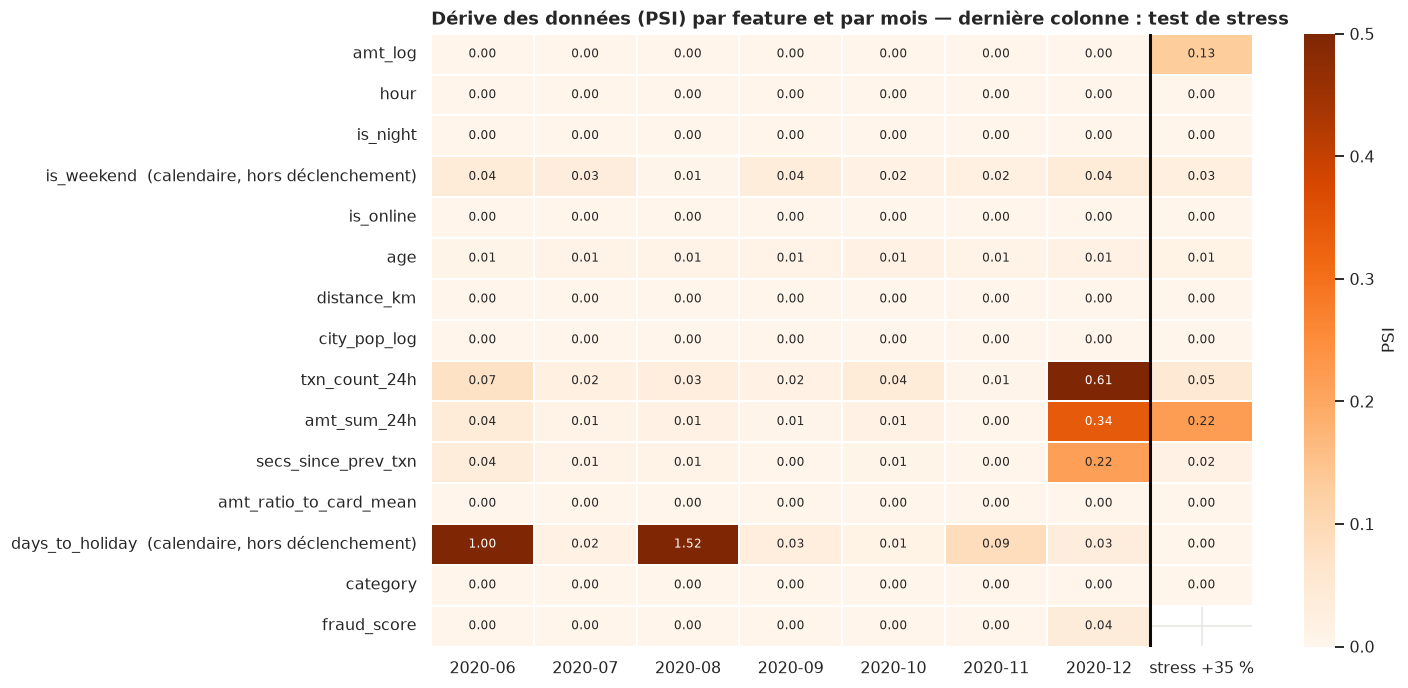

In [12]:
reference = silver.filter((F.col("dataset_split") == "train") & (F.col("trans_date") < C.VALIDATION_START)) \
    .select(*C.MONITORED_FEATURES).cache()
production = test_silver.select(*C.MONITORED_FEATURES, "trans_month").cache()
stress = (production
          .withColumn("amt_log", F.log1p(F.expm1("amt_log") * 1.35))
          .withColumn("amt_sum_24h", F.col("amt_sum_24h") * 1.35)
          .withColumn("trans_month", F.lit("stress +35 %")))

drift = pd.concat([
    psi_by_period(reference, production, C.MONITORED_FEATURES, "trans_month"),
    psi_by_period(reference, stress, C.MONITORED_FEATURES, "trans_month"),
], ignore_index=True)

valid_scores = score(champion, silver.filter((F.col("dataset_split") == "train") & (F.col("trans_date") >= C.VALIDATION_START))) \
    .select("fraud_score")
score_drift = psi_by_period(valid_scores, scored.select("fraud_score", "trans_month"), ["fraud_score"], "trans_month")
drift = pd.concat([drift, score_drift], ignore_index=True)

heat = drift.pivot(index="feature", columns="period", values="psi")
heat = heat.loc[[*C.MONITORED_FEATURES, "fraud_score"]]
heat.index = [f"{f}  (calendaire, hors déclenchement)" if f in C.DRIFT_EXCLUDED_FROM_TRIGGER else f for f in heat.index]
fig, ax = plt.subplots(figsize=(13.5, 6.4))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=0.5, linewidths=1, linecolor="white",
            cbar_kws={"label": "PSI"}, annot_kws={"fontsize": 8}, ax=ax)
ax.axvline(heat.columns.get_loc("stress +35 %"), color="#0b0b0b", lw=2)
ax.set_title("Dérive des données (PSI) par feature et par mois — dernière colonne : test de stress")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

period,transactions,frauds,alerts,precision,recall,pr_auc,max_feature_psi,retrain,retrain_reason
2020-06,"30,058",133,132,85.6%,85.0%,0.913,0.074,False,aucun déclencheur
2020-07,"85,848",321,303,89.4%,84.4%,0.919,0.022,False,aucun déclencheur
2020-08,"88,759",415,401,89.3%,86.3%,0.936,0.028,False,aucun déclencheur
2020-09,"69,533",340,319,91.5%,85.9%,0.942,0.015,False,aucun déclencheur
2020-10,"69,348",384,361,89.8%,84.4%,0.936,0.040,False,aucun déclencheur
2020-11,"72,635",294,285,90.9%,88.1%,0.933,0.013,False,aucun déclencheur
2020-12,"139,538",258,263,82.5%,84.1%,0.881,0.611,True,dérive de données (PSI max = 0.61 ≥ 0.25)
stress +35 %,"555,719",2145,4683,39.5%,86.2%,0.680,0.220,True,PR-AUC en baisse de plus de 10 % (0.680 vs 0.926)


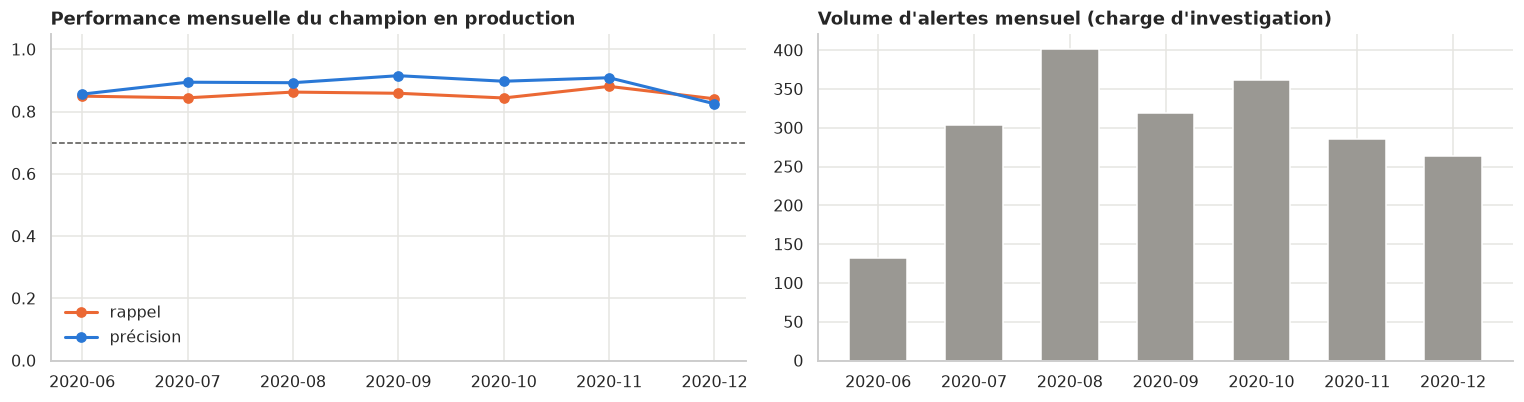

In [13]:
eval_pr = BinaryClassificationEvaluator(labelCol="is_fraud", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
perf_rows = []
months = [r[0] for r in scored.select("trans_month").distinct().orderBy("trans_month").collect()]
for m in months:
    sub = scored.filter(F.col("trans_month") == m).withColumn("is_fraud", F.col("is_fraud").cast("double"))
    a = sub.agg(F.count("*").alias("n"), F.sum("is_fraud").alias("k"),
                F.sum((F.col("fraud_score") >= thr).cast("int")).alias("alerts"),
                F.sum(((F.col("fraud_score") >= thr) & (F.col("is_fraud") == 1)).cast("int")).alias("tp")).first()
    perf_rows.append({"period": m, "transactions": a["n"], "frauds": int(a["k"]), "alerts": a["alerts"],
                      "precision": a["tp"] / a["alerts"] if a["alerts"] else np.nan, "recall": a["tp"] / a["k"] if a["k"] else np.nan,
                      "pr_auc": eval_pr.evaluate(sub) if a["k"] else np.nan})

stressed_scored = score(champion, test_silver.withColumn("amt_log", F.log1p(F.expm1("amt_log") * 1.35))
                        .withColumn("amt_sum_24h", F.col("amt_sum_24h") * 1.35)).withColumn("is_fraud", F.col("is_fraud").cast("double"))
a = stressed_scored.agg(F.count("*").alias("n"), F.sum("is_fraud").alias("k"),
                        F.sum((F.col("fraud_score") >= thr).cast("int")).alias("alerts"),
                        F.sum(((F.col("fraud_score") >= thr) & (F.col("is_fraud") == 1)).cast("int")).alias("tp")).first()
perf_rows.append({"period": "stress +35 %", "transactions": a["n"], "frauds": int(a["k"]), "alerts": a["alerts"],
                  "precision": a["tp"] / a["alerts"], "recall": a["tp"] / a["k"], "pr_auc": eval_pr.evaluate(stressed_scored)})
performance = pd.DataFrame(perf_rows)

trigger_features = drift[~drift["feature"].isin(["fraud_score", *C.DRIFT_EXCLUDED_FROM_TRIGGER])]
max_psi = trigger_features.groupby("period")["psi"].max()
decisions = [retraining_decision(float(max_psi.get(r.period, 0)), r.recall, C.QUALITY_GATES["test_recall"], r.pr_auc,
                                 float(BEST["test_pr_auc"])) for r in performance.itertuples()]
performance["max_feature_psi"] = performance["period"].map(max_psi).astype(float)
performance["retrain"] = [d[0] for d in decisions]
performance["retrain_reason"] = [d[1] for d in decisions]
display(performance.style.hide(axis="index").format(
    {"transactions": "{:,}", "precision": "{:.1%}", "recall": "{:.1%}", "pr_auc": "{:.3f}", "max_feature_psi": "{:.3f}"})
    .apply(lambda r: ["background-color: #eb683433" if r["retrain"] else "" for _ in r], axis=1))

prod = performance[performance["period"] != "stress +35 %"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(prod["period"], prod["recall"], color=FRAUD, lw=2, marker="o", label="rappel")
axes[0].plot(prod["period"], prod["precision"], color=LEGIT, lw=2, marker="o", label="précision")
axes[0].axhline(C.QUALITY_GATES["test_recall"], color="#52514e", ls="--", lw=1)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Performance mensuelle du champion en production")
axes[0].legend()
axes[1].bar(prod["period"], prod["alerts"], color=NEUTRAL, width=0.6)
axes[1].set_title("Volume d'alertes mensuel (charge d'investigation)")
plt.tight_layout()
plt.show()

In [14]:
# Journalisation du rapport de surveillance dans MLflow (run dédié, rattaché à la version servie)
with mlflow.start_run(run_name=f"monitoring-v{meta['model_version']}") as mon_run:
    mlflow.set_tags({"stage": "monitoring", "model_version": meta["model_version"], "projet": "FraudLake"})
    for step, r in enumerate(prod.itertuples()):
        mlflow.log_metrics({"monthly_recall": r.recall, "monthly_precision": r.precision, "monthly_pr_auc": r.pr_auc,
                            "monthly_max_psi": float(max_psi.get(r.period, 0))}, step=step)
    mlflow.log_text(drift.to_csv(index=False), "monitoring/psi_by_feature_month.csv")
    mlflow.log_text(performance.to_csv(index=False), "monitoring/performance_by_month.csv")
    mlflow.log_figure(fig, "monitoring/performance.png")

# Publication Gold pour le dashboard (le dashboard ne lit que la couche Gold)
def to_gold(pdf: pd.DataFrame, name: str) -> None:
    pdf = pdf.copy()
    for c in pdf.columns:
        if pd.api.types.is_string_dtype(pdf[c]) or pdf[c].dtype == object:
            pdf[c] = pdf[c].astype(object).where(pdf[c].notna(), None)
    spark.createDataFrame(pdf).coalesce(1).write.format("delta").mode("overwrite") \
        .option("overwriteSchema", "true").save(f"{C.GOLD_ROOT}/{name}")
    print(f"🥇 {C.GOLD_ROOT}/{name:<28} {len(pdf):>6,} lignes")


to_gold(experiments.assign(is_selected=lambda d: d["candidate"] == BEST["candidate"], data_version=DATA_VERSION), "mlops_experiments")
to_gold(registry, "mlops_model_registry")
to_gold(fairness, "mlops_fairness")
to_gold(gates.assign(valeur=lambda d: d["valeur"].astype(float)), "mlops_quality_gates")
to_gold(drift, "mlops_drift")
to_gold(performance, "mlops_performance_monthly")
to_gold(pd.DataFrame([{"model_version": str(mv.version), "champion_version": str(champion_version), "promoted": PROMOTED,
                       "tracking_uri": TRACKING_URI, "markdown": MODEL_CARD}]), "mlops_model_card")

catalog_updates = spark.createDataFrame(pd.DataFrame([
    {"table_name": "fraud_alerts", "description": "File d'alertes du champion : score, priorité, motifs lisibles (reason codes).",
     "sql": "PipelineModel champion (HDFS) → fraud_score ≥ seuil ; motifs : fraudlake.explain.RULES"},
    {"table_name": "mlops_experiments", "description": "Comparaison des 4 candidats suivis dans MLflow (PR-AUC validation/test, seuil, durée).",
     "sql": "MLflow Tracking — expérience fraudlake-scoring"},
    {"table_name": "mlops_model_registry", "description": "Versions du modèle dans le registre MLflow et leurs alias.",
     "sql": "MlflowClient.search_model_versions(name='fraudlake-scoring')"},
    {"table_name": "mlops_drift", "description": "PSI par feature et par mois de production (+ test de stress).",
     "sql": "fraudlake.monitoring.psi_by_period(référence = train, production = test, déciles de la référence)"},
    {"table_name": "mlops_performance_monthly", "description": "Précision, rappel, PR-AUC mensuels du champion et décision de ré-entraînement.",
     "sql": "fraudlake.monitoring.retraining_decision(PSI max, rappel, PR-AUC)"},
    {"table_name": "mlops_fairness", "description": "Rappel et précision du champion par genre et tranche d'âge.",
     "sql": "GROUP BY gender / tranche d'âge sur les prédictions test"},
]).assign(path=lambda d: C.GOLD_ROOT + "/" + d["table_name"], producer="J5_MLOps_Industrialisation")).withColumn("updated_at", F.current_timestamp())
catalog_path = f"{C.GOLD_ROOT}/data_catalog"
if DeltaTable.isDeltaTable(spark, catalog_path):
    (DeltaTable.forPath(spark, catalog_path).alias("c").merge(catalog_updates.alias("u"), "c.table_name = u.table_name")
     .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())

🏃 View run monitoring-v1 at: http://mlflow:5000/#/experiments/1/runs/8cfb46deeab941eeb474e1d354f94e91
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🥇 /lakehouse/gold/mlops_experiments                 5 lignes


🥇 /lakehouse/gold/mlops_model_registry              1 lignes


🥇 /lakehouse/gold/mlops_fairness                    6 lignes


🥇 /lakehouse/gold/mlops_quality_gates               4 lignes


🥇 /lakehouse/gold/mlops_drift                     119 lignes


🥇 /lakehouse/gold/mlops_performance_monthly         8 lignes


🥇 /lakehouse/gold/mlops_model_card                  1 lignes


> **Lecture de la surveillance.**
> - **Fausse alerte évitée** : en juin et août, `days_to_holiday` atteint un PSI de 1,0 à 1,5 — simple effet calendaire (août ne contient
>   aucun jour férié, juin est un mois partiel). Ces variables déterministes sont affichées mais **exclues du déclenchement**.
> - **Vraie dérive saisonnière en décembre** : `txn_count_24h` (PSI ≈ 0,61) et `amt_sum_24h` (≈ 0,34) basculent avec les achats de Noël ;
>   la précision tombe à 82 % (contre ≈ 90 % les autres mois) et la PR-AUC à 0,88. Le ré-entraînement est **légitimement déclenché** : le modèle n'a vu qu'un seul
>   décembre (2019) et devrait apprendre la saisonnalité (ou utiliser des features de vélocité relatives au mois).
> - **Test de stress (+35 % sur les montants)** : la dérive des données reste modérée (PSI 0,13 – 0,22, « à surveiller »), mais la
>   **précision s'effondre à 40 %** (4 683 alertes au lieu de ≈ 2 060) et la PR-AUC tombe à 0,68 → déclenchement via la règle de
>   performance. Les deux signaux (données **et** performance) sont donc complémentaires.
> - De juin à novembre, le modèle est stable (PSI < 0,1, rappel 84 – 88 %, précision 86 – 92 %) : aucun ré-entraînement inutile.

## 8. Exploitation : automatisation & procédures

| Événement | Action | Commande |
|---|---|---|
| Nouveau lot de données / dérive détectée (PSI ≥ 0,25) | ré-entraînement complet (J2 → J5) | `task mlops:retrain` |
| Nouveau champion promu | bascule à chaud de l'API | `curl -X POST localhost:8010/reload` |
| Régression constatée en production | **retour arrière** vers `@previous_champion` | alias MLflow + `/reload` (voir ci-dessous) |
| Modification du code partagé (`fraudlake/`, `serving/`) | CI : lint + 33 tests unitaires | GitHub Actions `.github/workflows/ci.yml` · `task test:unit` |
| Vérification du service | santé, latence, taux d'alerte | `task api:smoke` · `GET /health` · `GET /stats` |

```python
# Retour arrière en production (exemple) :
prev = client.get_model_version_by_alias("fraudlake-scoring", "previous_champion")
client.set_registered_model_alias("fraudlake-scoring", "champion", prev.version)
# puis ré-exporter cette version vers /lakehouse/models/fraudlake_scoring/champion et appeler POST /reload
```

---
## 🧾 Bilan du Jour 5
- ✅ **4 candidats** suivis dans MLflow avec données versionnées (Silver figée par Time Travel) : expériences reproductibles et comparables.
- ✅ **Validation sans fuite** : seuil choisi sur la validation, performance mesurée une seule fois sur une période future.
- ✅ **Portes qualité + équité** automatiques, registre MLflow `@champion` / `@challenger` / `@previous_champion`, fiche modèle.
- ✅ **Déploiement** : artefact HDFS + API FastAPI (rechargement à chaud), **scoring batch** expliqué (`gold/fraud_alerts`).
- ✅ **Surveillance** : PSI par feature, dérive du score, performance mensuelle ; le test de stress déclenche bien le ré-entraînement.